[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Harvard-CS1090/2026-CS1090A-public/blob/sec08-2026/sec08/cs1090a_sec08_student.ipynb)

> **On Colab, do `File → Save a copy in Drive` before you start.** This notebook opens from GitHub, so you can type in it and run it right away — but nothing is being saved anywhere. Close the tab and the work is gone. Saving a copy first gives you one that persists in your own Drive.

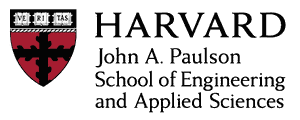

# CS1090A Introduction to Data Science

### Section 8 — Bayesian Inference for Heights and Health Outcomes

<div style="background:#E8F1FF; border-left:6px solid #2563EB; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🎯 Objectives — the core section</div>
<div>
<ul>
<li>Identify the prior, likelihood, and posterior and combine them with Bayes' rule.</li>
<li>Compute a normal posterior mean, standard deviation, and credible interval.</li>
<li>Explain the posterior mean as a weighted average, and predict the effects of prior uncertainty and sample size.</li>
<li>Extend the normal update to a regression slope.</li>
<li>Distinguish a credible interval's interpretation from confidence-interval coverage.</li>
</ul>
<p>The optional appendices include the full interval comparison, Beta-Bernoulli updating, and Bayesian logistic regression. They are not expected during this section.</p>
</div>
</div>

**Coloured boxes:** 🤔 commit to a prediction before running the code · 🏋️ write code (look for `# your code here`) · 💬 stop running cells and discuss · ⭐ the point of the exercise · 🧠 what to carry out of the room · 🔍 an appendix item to work through on your own afterwards.

**Bayesian inference** treats an unknown parameter, such as a population mean, as a quantity
with a probability distribution. Every model in this section has the same pieces. For a parameter $\theta$ and data $\mathbf y$:

- **Prior** $p(\theta)$: what we believe about $\theta$ before seeing these data, written as a probability distribution.
- **Likelihood** $p(\mathbf y\mid\theta)$: how probable the observed data are for each candidate value of $\theta$. It comes from our model for the observations.
- **Posterior** $p(\theta\mid\mathbf y)$: what we believe about $\theta$ after seeing the data.
- **Bayes' rule** combines likelihood and prior into the posterior:
$$p(\theta\mid\mathbf y)=\frac{p(\mathbf y\mid\theta)\,p(\theta)}{p(\mathbf y)}\;\propto\;p(\mathbf y\mid\theta)\,p(\theta).$$
The denominator $p(\mathbf y)$ does not depend on $\theta$. Its only job is to make the posterior integrate to 1, so we often write "$\propto$" (proportional to) and leave it out.

The core section has two models:

1. **Part 1:** the mean height of a population, with one unknown number and no predictors.
2. **Part 2:** a regression slope, adding a predictor to the normal observation model.

**Teaching focus:** understand the mean model first, then use the same updating idea for a slope. The brief interval discussion distinguishes posterior probability from repeated-sample coverage. The full analytical/bootstrap/Bayesian comparison is optional Appendix A1.

All data are simulated, so we know the generating parameter values and can compare estimates with them. These are not real measurements or claims about real populations.

**Optional reading after section:** A2 introduces a shared probability for a binary health outcome, and A3 adds age through logistic regression. These prepare the transition to numerical Bayesian inference, but are not required to finish the live section.

## Setup

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import expit
from sklearn.linear_model import LinearRegression, Ridge

plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

### Simulated adult heights

We simulate heights from a normal distribution with mean `true_mu` = 175 cm and standard deviation `sigma` = 7 cm.
In the analysis we pretend that we do not know the mean, but we treat `sigma` as known, which keeps the formulas short.
We draw 1,200 heights once. Most of Part 1 uses the first 12; later we use the first 120 and then all 1,200.

Our prior for the mean is $N(168, 2^2)$: before seeing data, we believe the mean is near 168 cm and very likely within
about 4 cm (two prior standard deviations) of it. We chose a prior that is centred away from the true value on purpose,
so that its effect on the posterior is easy to see.

In [ ]:
rng_height = np.random.default_rng(109)
true_mu, sigma = 175.0, 7.0                         # generating mean and known observation SD (cm)
height_sequence = rng_height.normal(true_mu, sigma, 1200)
y_height = height_sequence[:12]                     # the first 12 heights
mu_p, sigma_p = 168.0, 2.0                          # prior mean and prior SD for the population mean (cm)
pd.Series({"n": len(y_height), "sample mean (cm)": y_height.mean(),
           "known observation SD (cm)": sigma, "prior mean (cm)": mu_p,
           "prior SD (cm)": sigma_p}).round(3)

## Part 1. A normal model for a population mean

### The model, the prior, and the likelihood

Each height is the population mean plus random noise:

$$y_i=\mu+\epsilon_i,\qquad \epsilon_i\overset{\mathrm{ind}}{\sim}N(0,\sigma^2),
\qquad\text{so}\qquad y_i\mid\mu\sim N(\mu,\sigma^2).$$

This is the intercept-only regression model: every person has the same predicted height, $\mu$.

Two normal distributions appear in this part, and they describe different things:

| | What it describes | Standard deviation |
|---|---|---|
| Observation model $y_i\mid\mu\sim N(\mu,\sigma^2)$ | how **individual heights** vary around the mean | $\sigma = 7$ cm, known |
| Prior $\mu\sim N(\mu_p,\sigma_p^2)$ | our uncertainty about the **population mean** before seeing data | $\sigma_p = 2$ cm, chosen by us |

The **likelihood** is the probability density of the observed data, viewed as a function of a candidate value of $\mu$.
Because the observations are independent, we multiply their normal densities:

$$L(\mu)=p(\mathbf y\mid\mu)\propto\exp\left[-\frac{\sum_i(y_i-\mu)^2}{2\sigma^2}\right].$$

The likelihood is not a probability distribution over $\mu$; it does not have to integrate to 1.
Multiplying it by the prior gives the posterior, up to a constant:

$$p(\mu\mid\mathbf y)\propto
\underbrace{\exp\left[-\frac{\sum_i(y_i-\mu)^2}{2\sigma^2}\right]}_{\text{likelihood}}\;
\underbrace{\exp\left[-\frac{(\mu-\mu_p)^2}{2\sigma_p^2}\right]}_{\text{prior}}.$$

### The closed-form normal posterior

A prior is **conjugate** to a likelihood when the posterior belongs to the same family of distributions as the prior.
Here both exponents in the posterior are quadratic in $\mu$. Adding them and completing the square (Appendix A7) gives another normal distribution,
$\mu\mid\mathbf y\sim N(\mu_{\mathrm{post}},\sigma_{\mathrm{post}}^2)$, with

$$\boxed{\mu_{\mathrm{post}}=
\frac{n\sigma_p^2}{n\sigma_p^2+\sigma^2}\bar y+
\frac{\sigma^2}{n\sigma_p^2+\sigma^2}\mu_p},\qquad
\boxed{\sigma_{\mathrm{post}}^2=\frac{\sigma^2\sigma_p^2}{n\sigma_p^2+\sigma^2}}.$$

This is the formula from lecture, where the prior mean and SD are written $\mu_0$ and $\sigma_0$.

The posterior mean is a **weighted average** of the sample mean $\bar y$ and the prior mean $\mu_p$. Write the weight on the data as

$$w=\frac{n\sigma_p^2}{n\sigma_p^2+\sigma^2},\qquad\text{so}\qquad \mu_{\mathrm{post}}=w\,\bar y+(1-w)\,\mu_p.$$

The weight $w$ grows when $n$ grows and when the prior SD $\sigma_p$ grows. In our example $n\sigma_p^2=12\times4=48$ and $\sigma^2=49$,
so $w=48/97\approx0.49$: the data and the prior get almost equal weight.

The posterior standard deviation $\sigma_{\mathrm{post}}$ is the square root of the posterior variance. It measures our uncertainty about
the **mean**. The standard deviation of individual heights stays $\sigma=7$ cm.

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 1: update the mean (4 min)</div>
<div>
Complete the two formulas in <code>normal_mean_posterior</code>, using the boxed formulas above. Return the posterior mean and the posterior
<em>standard deviation</em>, not the variance. Run the next cell to summarize the result. Check that the posterior mean is between the prior mean and the sample mean, and that the posterior SD is smaller than the prior SD.
</div>
</div>

In [ ]:
def normal_mean_posterior(y, sigma, mu_p, sigma_p):
    n = len(y)
    denominator = n * sigma_p**2 + sigma**2
    mean = ...  # your code here
    variance = ...  # your code here
    return mean, np.sqrt(variance)

In [ ]:
mean_post, sd_post = normal_mean_posterior(y_height, sigma, mu_p, sigma_p)
mean_interval = stats.norm.interval(0.95, loc=mean_post, scale=sd_post)
pd.Series({"prior mean (cm)": mu_p, "sample mean (cm)": y_height.mean(),
           "posterior mean (cm)": mean_post, "posterior SD (cm)": sd_post,
           "95% credible lower (cm)": mean_interval[0],
           "95% credible upper (cm)": mean_interval[1]}).round(3)

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 1: interpreting the interval</div>
<div>
<ol><li>What does the 95% credible interval say about the unknown mean?</li><li>Is it an interval that contains 95% of individual heights?</li><li>Which standard deviation describes how individual heights vary, and which describes our prior uncertainty about the mean?</li></ol>
</div>
</div>

### Changing the prior standard deviation

<div style="background:#FFF7CC; border-left:6px solid #D97706; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🤔 Predict — a narrower or wider prior</div>
<div>
Keep the data and the prior mean (168 cm) fixed, and try prior SDs of 0.7, 2 and 10 cm. As the prior SD gets smaller, will the posterior mean move
toward the prior mean or toward the sample mean? Will the posterior SD get larger or smaller? Commit before running the cell.
</div>
</div>

In [ ]:
mu_grid = np.linspace(150, 195, 2401)  # horizontal axis for the density plots
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True, sharey=True)
prior_rows = []
for ax, prior_sd in zip(axes, [0.7, 2.0, 10.0]):
    m, s = normal_mean_posterior(y_height, sigma, mu_p, prior_sd)
    w = len(y_height) * prior_sd**2 / (len(y_height) * prior_sd**2 + sigma**2)   # weight on the sample mean
    ax.plot(mu_grid, stats.norm.pdf(mu_grid, mu_p, prior_sd), label="Prior")
    ax.plot(mu_grid, stats.norm.pdf(mu_grid, m, s), label="Posterior")
    ax.axvline(y_height.mean(), color="grey", linestyle="--", label="Sample mean")
    ax.set(title=f"Prior SD = {prior_sd} cm", xlabel="Population mean (cm)", xlim=(160, 186))
    prior_rows.append([prior_sd, w, m, s])
axes[0].set_ylabel("Density"); axes[-1].legend(fontsize=9)
fig.tight_layout(); plt.show()
pd.DataFrame(prior_rows, columns=["prior SD", "weight on sample mean", "posterior mean", "posterior SD"]).round(3)

With a prior SD of 0.7 cm the data get weight 0.11, so the posterior mean (168.8 cm) stays close to the prior mean, and the posterior SD is only 0.66 cm.
With a prior SD of 10 cm the data get weight 0.96, so the posterior mean (175.3 cm) is close to the sample mean, and the posterior SD (1.98 cm) is close to
$\sigma/\sqrt{n}=2.02$ cm. The left panel is the case to watch for: a narrow prior gives a narrow posterior even when the prior mean is wrong.
The true mean is 175 cm, and that posterior puts almost no probability there.

### Increasing the sample size

Now keep the prior fixed at $N(168, 2^2)$ and use the first 12, the first 120, and all 1,200 simulated heights.
Because each larger sample contains the smaller one, the sample mean changes only because new observations are added.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True)
size_rows = []
for ax, n in zip(axes, [12, 120, 1200]):
    y_n = height_sequence[:n]
    m, s = normal_mean_posterior(y_n, sigma, mu_p, sigma_p)
    w = n * sigma_p**2 / (n * sigma_p**2 + sigma**2)          # weight on the sample mean
    ax.plot(mu_grid, stats.norm.pdf(mu_grid, mu_p, sigma_p), label="Fixed prior")
    ax.plot(mu_grid, stats.norm.pdf(mu_grid, m, s), label="Posterior")
    ax.axvline(y_n.mean(), color="grey", linestyle="--", label="Sample mean")
    ax.axvline(true_mu, color="black", linestyle=":", label="True mean")
    ax.set(title=f"n = {n}", xlabel="Population mean (cm)", xlim=(160, 186))
    size_rows.append([n, y_n.mean(), w, m, s])
axes[0].set_ylabel("Density"); axes[-1].legend(fontsize=8)
fig.tight_layout(); plt.show()
pd.DataFrame(size_rows, columns=["n", "sample mean", "weight on sample mean", "posterior mean", "posterior SD"]).round(3)

<div style="background:#F3E8FF; border-left:6px solid #7E22CE; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">⭐ Insight — what controls the posterior</div>
<div>
<ul>
<li><strong>A smaller prior SD σ<sub>p</sub> puts more weight on the prior mean.</strong> The posterior mean moves toward μ<sub>p</sub> and the posterior SD shrinks. If μ<sub>p</sub> is far from the truth, the result is a narrow posterior around the wrong value.</li>
<li><strong>A larger sample size n puts more weight on the sample mean.</strong> The weight on the data went from 0.49 at n = 12 to 0.99 at n = 1,200, and the posterior SD shrank from 1.42 to 0.20 cm. This holds for any normal prior. A prior that gives zero probability to some values is different: no amount of data can move the posterior to those values.</li>
<li>The prior and the data get equal weight when nσ<sub>p</sub>² = σ². With σ<sub>p</sub> = 2 and σ = 7 that happens at n ≈ 12, which is why our first posterior sat halfway between 168 and 175.6 cm.</li>
</ul>
</div>
</div>

### A very wide prior

If the prior SD is very large ($\sigma_p\to\infty$), the prior has almost no preference among candidate means. Then $w\to1$ and

$$\mu_{\mathrm{post}}\to\bar y,\qquad \sigma_{\mathrm{post}}\to\frac{\sigma}{\sqrt n}.$$

A prior like this is called **diffuse**. Its influence is small compared with the information in the data. Appendix A1 compares its credible interval with confidence intervals numerically.

## Part 2. Adding a predictor: a regression slope

### From one mean to a regression line

Now we also record each person's parent's height, $x_i$. Instead of one mean for everyone, the mean height depends on $x_i$:

$$y_i=\beta_0+\beta_1x_i+\epsilon_i,\qquad
 y_i\mid x_i,\beta_0,\beta_1\sim N(\beta_0+\beta_1x_i,\sigma^2).$$

These are the usual linear-regression assumptions: the mean is linear in $x$; the errors are independent, so the likelihood is a product;
every observation has the same error variance $\sigma^2$ (**homoscedasticity**); and the errors are normal. As in Part 1, $\sigma=7$ cm is known.

We simulate 80 parent–child pairs with a true slope of 0.65: each extra centimetre of parent height adds 0.65 cm to the expected adult-child height.
This is a simulation for practising the method, not a study of how height is inherited.

In [ ]:
rng_regression = np.random.default_rng(110)
x = rng_regression.normal(170, 8, 80)               # parent heights (cm)
true_slope = 0.65
sigma_reg = 7.0                                     # known observation SD (cm)
reg_y = 175 + true_slope * (x - 170) + rng_regression.normal(0, sigma_reg, len(x))
x_bar, y_bar = x.mean(), reg_y.mean()
x_c, y_c = x - x_bar, reg_y - y_bar                 # centred predictor and response
ols = LinearRegression().fit(x[:, None], reg_y)
beta_hat = ols.coef_[0]
print(f"OLS slope: {beta_hat:.3f} cm per cm   (true slope: {true_slope})")

In [ ]:
x_line = np.linspace(x.min() - 2, x.max() + 2, 150)
fig, ax = plt.subplots()
ax.scatter(x, reg_y, alpha=0.6, label="Simulated observations")
ax.plot(x_line, ols.predict(x_line[:, None]), color="black", label="OLS mean response")
ax.set(xlabel="Parent height (cm)", ylabel="Adult-child height (cm)")
ax.legend(); plt.show()

### A normal prior on the slope

We put a normal prior on the slope only:

$$\beta_1\sim N(\mu_{\beta_1},\sigma_{\beta_1}^2).$$

We put no prior information on the intercept. Mathematically, this is a **flat prior**: every intercept value is treated as equally plausible. A constant density over all real intercepts cannot integrate to 1, so this prior is called **improper**; a **proper** prior integrates to 1. The likelihood in this example still gives a proper posterior for the intercept.

The update for the slope is the Part 1 update with three substitutions:

| | Part 1: the mean | Part 2: the slope |
|---|---|---|
| Estimate from the data | sample mean $\bar y$ | OLS slope $\hat\beta_1=\dfrac{\sum_i(x_i-\bar x)(y_i-\bar y)}{S_{xx}}$ |
| Amount of information in the data | sample size $n$ | $S_{xx}=\sum_i(x_i-\bar x)^2$ |
| Prior | $N(\mu_p,\sigma_p^2)$ | $N(\mu_{\beta_1},\sigma_{\beta_1}^2)$ |

Making those substitutions in the Part 1 formulas gives

$$\boxed{\mu_{\beta_1,\mathrm{post}}=
\frac{S_{xx}\sigma_{\beta_1}^2}{S_{xx}\sigma_{\beta_1}^2+\sigma^2}\hat\beta_1+
\frac{\sigma^2}{S_{xx}\sigma_{\beta_1}^2+\sigma^2}\mu_{\beta_1}},\qquad
\boxed{\sigma_{\beta_1,\mathrm{post}}^2=
\frac{\sigma^2\sigma_{\beta_1}^2}{S_{xx}\sigma_{\beta_1}^2+\sigma^2}}.$$

**Why $S_{xx}$ takes the place of $n$.** The sample mean has sampling variance $\sigma^2/n$, and the OLS slope has sampling variance $\sigma^2/S_{xx}$.
$S_{xx}$ is large when there are many observations *and* their $x$ values are spread out. If every $x_i$ were the same, $S_{xx}$ would be 0 and the
data would say nothing about the slope.

**Where the intercept went.** To obtain the slope posterior, we account for every possible intercept by integrating over that parameter with its flat prior. This leaves a likelihood for the slope alone that is proportional to $\exp[-S_{xx}(\beta_1-\hat\beta_1)^2/(2\sigma^2)]$. This has the same form as the
Part 1 likelihood, with $\hat\beta_1$ in place of $\bar y$ and $S_{xx}$ in place of $n$. Centering $x$ is what separates the slope from the intercept in this calculation;
centering $y$ only shortens the code. The intercept is still uncertain, and Appendix A6 shows how that uncertainty enters predictions.

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 2: update the slope (5 min)</div>
<div>
Complete the posterior mean and variance in <code>slope_posterior</code>, using the boxed formulas. Return the mean and the standard deviation.
<br><br>
The prior used below is <em>N</em>(0, 0.12²). It is a sceptical prior: before seeing data, it says the slope is probably within about ±0.24 cm per cm of zero (two prior SDs).
The OLS slope is 0.649. <strong>Predict before running:</strong> will the posterior mean be below or above the OLS estimate, and will its uncertainty be smaller or larger than with a diffuse prior?
</div>
</div>

In [ ]:
sxx = np.dot(x_c, x_c)                               # S_xx, the spread of the predictor
mu_beta1, sigma_beta1 = 0.0, 0.12

def slope_posterior(beta_hat, sxx, sigma, mu_beta1, sigma_beta1):
    denominator = sxx * sigma_beta1**2 + sigma**2
    mean = ...  # your code here
    variance = ...  # your code here
    return mean, np.sqrt(variance)

In [ ]:
slope_mean, slope_sd = slope_posterior(beta_hat, sxx, sigma_reg, mu_beta1, sigma_beta1)
diffuse_slope_mean, diffuse_slope_sd = slope_posterior(beta_hat, sxx, sigma_reg, 0, 1e6)
w_slope = sxx * sigma_beta1**2 / (sxx * sigma_beta1**2 + sigma_reg**2)
slope_interval = stats.norm.interval(0.95, loc=slope_mean, scale=slope_sd)
print(f"S_xx = {sxx:.0f}; weight on OLS estimate = {w_slope:.2f}; prior weight = {1-w_slope:.2f}")
pd.Series({"OLS slope": beta_hat, "posterior mean": slope_mean,
           "posterior SD": slope_sd, "95% credible lower": slope_interval[0],
           "95% credible upper": slope_interval[1]}).round(3)

In [ ]:
slope_grid = np.linspace(0, beta_hat + 5*diffuse_slope_sd, 1000)
fig, ax = plt.subplots()
ax.plot(slope_grid, stats.norm.pdf(slope_grid, diffuse_slope_mean, diffuse_slope_sd), label="Diffuse-prior posterior", color="tab:blue")
ax.plot(slope_grid, stats.norm.pdf(slope_grid, slope_mean, slope_sd), label="Informative-prior posterior", color="tab:orange")
ax.axvline(true_slope, color="black", linestyle=":", label="Generating slope")
ax.set(xlabel="Slope (cm per cm of parent height)", ylabel="Posterior density")
ax.legend(fontsize=9); plt.show()

### Credible intervals and confidence intervals

A 95% **credible interval** contains 95% posterior probability for the parameter, conditional on the observed data, the observation model, and the prior.

A 95% **confidence-interval procedure** produces intervals that cover the fixed true parameter in 95% of repeated samples under its assumptions. It does not assign probability to that fixed parameter for one observed interval. Approximate procedures need not achieve exactly 95% coverage.

Their endpoints can be similar or even equal in special cases without these statements being interchangeable. Appendix A1 gives the numerical comparison, including bootstrap intervals; we do not need to run that comparison during section.

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 2: the slope update and interval meaning</div>
<div>
<ol><li>Why did the informative prior change the slope estimate and its uncertainty?</li><li>Does its 95% credible interval describe 95% of individual child heights, or uncertainty about the slope?</li><li>How would the interpretation differ for a confidence-interval procedure?</li></ol>
</div>
</div>

<div style="background:#F3F4F6; border-left:6px solid #4B5563; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🧠 Takeaways — the core section</div>
<div>
<ol>
<li><strong>Multiplying the likelihood and prior and normalizing gives the posterior.</strong> Every posterior statement depends on the observation model and the prior assumptions.</li>
<li><strong>The normal updates balance prior and data information.</strong> The data estimate is the sample mean for Part 1 and the OLS slope for Part 2. A narrower prior increases the weight on its mean; more observations increase the data weight for a mean. For a slope, information grows with S<sub>xx</sub>, so additional observations help when their predictor values are spread out.</li>
<li><strong>Credible intervals and confidence procedures have different interpretations.</strong> The first describes posterior probability; the second describes repeated-sample coverage.</li>
</ol>
<p><strong>Final check:</strong> Which of σ, σ<sub>p</sub>, and n describes individual-height variation, prior uncertainty about the mean, and sample size? What replaces n in the slope update?</p>
<p><strong>The live section ends here.</strong> All appendices below are optional material for later.</p>
</div>
</div>

---

## Appendix — optional material for later

None of the following needs to be covered in the live section. The examples assume you have run Parts 1–2; later appendices do not depend on running earlier optional appendices unless stated.

- **A1. Interval comparisons:** analytical confidence intervals, bootstrap percentile intervals, and diffuse/informative Bayesian credible intervals.
- **A2. Beta-Bernoulli updating:** one shared probability for a binary outcome, with optional Exercise 3.
- **A3. Bayesian logistic regression:** add age to A2's model and motivate future sampling methods. Run A2 first.
- **A4. Multiple linear regression:** a multivariate normal posterior.
- **A5. Ridge regression:** a zero-mean normal prior as a penalty.
- **A6. Prediction uncertainty:** a mean response versus a new observation.
- **A7. Grid calculation, derivations, and unknown noise:** verify the normal update and account for uncertainty in σ.

An optional section exercise is not a statement about homework coverage; use the homework prompts to determine what you need there.

### A1. Analytical, bootstrap, and Bayesian interval comparisons

This extends the brief interpretation discussion in Part 2. All computation below is provided; there are no extra core exercises. We use the same observations and known noise SD as Parts 1–2.

#### A very wide prior and the confidence interval

If we make the prior SD very large ($\sigma_p\to\infty$), the prior has almost no preference among candidate means. Then $w\to1$ and

$$\mu_{\mathrm{post}}\to\bar y,\qquad \sigma_{\mathrm{post}}\to\frac{\sigma}{\sqrt n}.$$

A prior like this is called **diffuse**. With known $\sigma$, the 95% credible interval then has the same endpoints as the familiar
confidence interval $\bar y\pm1.96\,\sigma/\sqrt n$, as the table below shows. The two intervals still mean different things:

- The **credible interval** says: given these data and this prior, the posterior assigns probability 0.95 to mean values in the interval.
- A 95% **confidence-interval procedure** says: if we repeated the whole study many times and built an interval each time, 95% of those intervals
would contain the fixed true mean. It does not give a probability for the mean from one observed interval.

In [ ]:
diffuse_mean, diffuse_sd = normal_mean_posterior(y_height, sigma, mu_p, 1e6)   # prior SD of a million cm
se = sigma / np.sqrt(len(y_height))
pd.DataFrame({"centre": [diffuse_mean, y_height.mean()],
              "SD or SE": [diffuse_sd, se],
              "95% lower": [diffuse_mean - 1.96 * diffuse_sd, y_height.mean() - 1.96 * se],
              "95% upper": [diffuse_mean + 1.96 * diffuse_sd, y_height.mean() + 1.96 * se]},
             index=["Diffuse-prior credible interval", "Confidence interval"]).round(3)

#### Bootstrap uncertainty for the slope (review from Section 5)

This is the paired bootstrap from Section 5, Part 2: resample the 80 rows with replacement, refit, record the slope, and repeat 3,000 times.
The spread of those slopes estimates how much the OLS slope would vary from one sample to another. It is not a posterior:
no prior is involved, and it does not give a probability for the slope itself. The loop is provided.

In [ ]:
rng_boot = np.random.default_rng(111)
boot_slopes = np.empty(3000)
for b in range(len(boot_slopes)):
    idx = rng_boot.integers(0, len(x), size=len(x))     # resample rows with replacement
    xb, yb = x[idx], reg_y[idx]
    xb_c, yb_c = xb - xb.mean(), yb - yb.mean()
    boot_slopes[b] = np.dot(xb_c, yb_c) / np.dot(xb_c, xb_c)   # OLS slope on the resample
bootstrap_interval = np.quantile(boot_slopes, [0.025, 0.975])
print(f"Bootstrap slopes: mean {boot_slopes.mean():.3f}, SD {boot_slopes.std(ddof=1):.3f}")

In [ ]:
analytical_se = sigma_reg / np.sqrt(sxx)
interval_rows = []
for label, m, s in [("Analytical CI (known sigma)", beta_hat, analytical_se),
                     ("Diffuse-prior credible interval", diffuse_slope_mean, diffuse_slope_sd),
                     ("Informative-prior credible interval", slope_mean, slope_sd)]:
    lo, hi = stats.norm.interval(0.95, loc=m, scale=s)
    interval_rows.append([label, m, s, lo, hi])
interval_rows.append(["Bootstrap percentile CI", boot_slopes.mean(), boot_slopes.std(ddof=1), *bootstrap_interval])
interval_table = pd.DataFrame(interval_rows, columns=["method", "centre", "SD or SE", "95% lower", "95% upper"])
interval_table.round(3)

In [ ]:
slope_grid = np.linspace(min(0, slope_mean - 5*slope_sd), beta_hat + 5*analytical_se, 1000)
fig, ax = plt.subplots()
ax.hist(boot_slopes, bins=40, density=True, alpha=0.3, label="Bootstrap estimates")
ax.plot(slope_grid, stats.norm.pdf(slope_grid, diffuse_slope_mean, diffuse_slope_sd), label="Diffuse-prior posterior", color="tab:blue")
ax.plot(slope_grid, stats.norm.pdf(slope_grid, slope_mean, slope_sd), label="Informative-prior posterior", color="tab:orange")
ax.axvline(true_slope, color="black", linestyle=":", label="Generating slope")
ax.set(xlabel="Slope (cm per cm of parent height)", ylabel="Density")
ax.legend(fontsize=9); plt.show()

#### Comparing the four intervals

- The **analytical CI** is $\hat\beta_1\pm1.96\,\sigma/\sqrt{S_{xx}}$, the frequentist confidence interval when $\sigma$ is known.
- The **diffuse-prior credible interval** comes from a very wide prior. Then the posterior is $N(\hat\beta_1,\sigma^2/S_{xx})$, so its endpoints equal the analytical CI's.
- In the **informative-prior credible interval**, the $N(0, 0.12^2)$ prior gets weight 0.41, which moves the centre from 0.649 to 0.385 and makes the interval narrower.
Its interval does not contain the true slope of 0.65: this is the narrow-prior-around-a-wrong-value case from Part 1.
- The **bootstrap percentile CI** uses the 2.5th and 97.5th percentiles of the 3,000 bootstrap slopes. It is close to the analytical CI here.
Its 95% coverage is approximate, not exact.

Three of the four rows give nearly the same numbers, but a credible interval and a confidence interval answer different questions, as discussed in Part 2.

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Optional discussion A1: the interval comparison</div>
<div>
<ol><li>Which rows of the table use a prior? Why do the two credible intervals differ?</li><li>What does "95%" refer to for a credible interval, and what does it refer to for a confidence interval?</li><li>Would running 100 times as many bootstrap resamples make the bootstrap interval agree with the informative-prior interval?</li></ol>
</div>
</div>

#### Bootstrap repetitions and observations

Increasing the number of bootstrap resamples for fixed data reduces simulation noise in the percentile estimates. It need not make them equal the analytical interval or a Bayesian interval. Increasing the number of observed people is a different limit. With more observations, a correctly specified regular model, a valid bootstrap, and a fixed prior with continuous positive density near the true value, these intervals can agree approximately in centre and width. Every nondegenerate normal prior satisfies this prior condition, even when its mean is far from the truth. Their interpretations still differ.

### A2. Beta-Bernoulli updating for a shared probability

This is an optional extension from a continuous response to a binary outcome. It is not a third part to reach during section.

#### A shared probability for a health outcome

We simulate 24 adults, each with an age and a yes/no heart-disease outcome (1 = disease, 0 = no disease).
In the simulation, the probability of disease rises with age. This is a teaching simulation, not a clinical risk estimate.

We start by ignoring age. Every person gets the same unknown probability $p$ of disease:

$$y_i\sim\mathrm{Bernoulli}(p),\quad\text{independently}.$$

This is the yes/no version of Part 1, where everyone had the same mean $\mu$. A Bernoulli observation is a binomial with one trial,
so the number of positive outcomes, $k=\sum_i y_i$, follows a $\mathrm{Binomial}(n,p)$ distribution.

Because ages are sampled independently from the same population, the shared probability p describes the population-average disease probability when age is ignored. It does not describe differences in probability conditional on age.

In [ ]:
rng_health = np.random.default_rng(112)
age_z = rng_health.normal(size=24)
age = 50 + 10 * age_z                                 # ages, mean 50 and SD 10 years
true_prob = expit(-0.6 + 0.8 * age_z)                 # true disease probability rises with age
y_health = rng_health.binomial(1, true_prob)
health = pd.DataFrame({"age": age, "heart_disease": y_health})
n_health, k_health = len(y_health), y_health.sum()
print(f"Observed disease outcomes: {k_health} of {n_health}; proportion = {k_health/n_health:.3f}")
health.head().round(1)

#### A Beta prior and posterior

The parameter $p$ is a probability, so its prior must only allow values between 0 and 1. The **Beta distribution** $\mathrm{Beta}(a,b)$
is a distribution on $[0,1]$ with density proportional to $p^{a-1}(1-p)^{b-1}$ and mean $a/(a+b)$. $\mathrm{Beta}(1,1)$ is flat: every value of $p$ is equally plausible.

For $k$ positive outcomes among $n$ independent observations, the likelihood is proportional to $p^k(1-p)^{n-k}$.
Multiplying it by the Beta prior adds the exponents:

$$p(p\mid\mathbf y)\propto p^{a+k-1}(1-p)^{b+n-k-1},\qquad\text{so}\qquad
p\mid\mathbf y\sim\mathrm{Beta}(a+k,b+n-k).$$

The posterior is again a Beta distribution, so the Beta prior is conjugate here. The update adds the $k$ observed positive outcomes to $a$ and the $n-k$
observed negative outcomes to $b$. The sum $a+b$ acts as a prior weight in the posterior-mean identity below. These shape parameters need not be literal counts from an earlier sample.

The posterior mean is again a weighted average, this time of the prior mean and the observed proportion:

$$\mathbb E[p\mid\mathbf y]=\frac{a+b}{a+b+n}\cdot\frac{a}{a+b}+\frac{n}{a+b+n}\cdot\frac{k}{n}.$$

The prior mean gets weight $a+b$ and the observed proportion gets weight $n$. To specify a prior by its mean $m$ and weight $w$, set $a=mw$ and $b=(1-m)w$.

We compare two priors: the flat $\mathrm{Beta}(1,1)$, with weight 2, and $\mathrm{Beta}(20,20)$, with mean 0.5 and weight 40, which is more than our $n=24$.

In [ ]:
p_grid = np.linspace(0.001, 0.999, 1000)
health_priors = {"Flat: Beta(1, 1)": (1, 1), "Stronger: Beta(20, 20)": (20, 20)}
fig, ax = plt.subplots()
for label, (a, b) in health_priors.items():
    ax.plot(p_grid, stats.beta.pdf(p_grid, a, b), label=label)
ax.set(xlabel="Shared disease probability p", ylabel="Prior density")
ax.legend(); plt.show()

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Optional Exercise 3: update a shared probability (3 min)</div>
<div>
For each prior, fill in the two posterior shape parameters, <code>a_post</code> and <code>b_post</code>. The rest of the code reports the posterior mean and the central 95% credible interval.
It uses <code>stats.beta.ppf</code>, which computes quantiles of the Beta distribution. A Beta posterior need not be symmetric, so we do not use mean ± 1.96 SD.
</div>
</div>

In [ ]:
beta_rows = []
health_posteriors = {}
for label, (a, b) in health_priors.items():
    a_post = ...  # your code here
    b_post = ...  # your code here
    health_posteriors[label] = (a_post, b_post)
    lo, hi = stats.beta.ppf([0.025, 0.975], a_post, b_post)
    beta_rows.append([label, a_post/(a_post+b_post), lo, hi])
pd.DataFrame(beta_rows, columns=["prior", "posterior mean", "95% lower", "95% upper"]).round(3)

In [ ]:
fig, ax = plt.subplots()
for label, (a_post, b_post) in health_posteriors.items():
    ax.plot(p_grid, stats.beta.pdf(p_grid, a_post, b_post), label=label)
ax.axvline(k_health/n_health, color="black", linestyle="--", label="Observed proportion")
ax.set(xlabel="Shared disease probability p", ylabel="Posterior density")
ax.legend(); plt.show()

Under the flat prior the posterior mean, 0.385, is close to the observed proportion of 0.375, because the prior's weight of 2 is small next to n = 24.
Under Beta(20, 20) the prior's weight of 40 is larger than n = 24, so the posterior mean, 0.453, is closer to the prior mean of 0.5 than to the data.

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Optional discussion A2: adding predictors</div>
<div>
<ol><li>What do we assume when we give everyone the same disease probability?</li><li>Which recorded variable could explain why some people have a higher probability than others?</li><li>Could a Beta prior on one shared probability describe those differences?</li></ol>
</div>
</div>

### A3. Bayesian logistic regression and the next computational question

Run A2 first: this example reuses its ages and binary outcomes. It is optional preparation for the sampling material, not an additional live-section target.

#### Logistic regression: a probability that depends on age

Now we use age. Each person gets their own probability $p_i$, which depends on their standardized age $x_i$ through the logistic function from Section 7:

$$\eta_i=\beta_0+\beta_1x_i,\qquad p_i=\frac{1}{1+e^{-\eta_i}},\qquad
 y_i\mid x_i,\boldsymbol\beta\sim\mathrm{Bernoulli}(p_i).$$

The outcome is still Bernoulli. What changed is the probability: one shared $p$ has become a $p_i$ for each person.

The unknowns are now the coefficients $\beta_0$ and $\beta_1$, which can be any real numbers, so a Beta prior no longer applies. We give **both** coefficients
independent normal priors, $\beta_j\sim N(0,2^2)$. Unlike Part 2, the intercept gets a proper prior too, which guarantees the posterior is a valid distribution even in a small sample.
Because age is standardized, a prior SD of 2 says that, before seeing data, a one-observed-SD increase in age is very unlikely to change the log-odds by more than about 4.

The likelihood is $\prod_i p_i^{y_i}(1-p_i)^{1-y_i}$, and we multiply it by the prior once:

$$p(\boldsymbol\beta\mid\mathbf x,\mathbf y)\propto
\left[\prod_i p_i^{y_i}(1-p_i)^{1-y_i}\right]
\exp\left[-\frac{\beta_0^2}{2\sigma_{\beta_0}^2}-\frac{\beta_1^2}{2\sigma_{\beta_1}^2}\right].$$

Taking logs gives

$$\log p(\boldsymbol\beta\mid\mathbf x,\mathbf y)=
\underbrace{\sum_i\left[y_i\eta_i-\log(1+e^{\eta_i})\right]}_{\text{log-likelihood}}
\;\underbrace{-\frac{\beta_0^2}{2\sigma_{\beta_0}^2}-\frac{\beta_1^2}{2\sigma_{\beta_1}^2}}_{\text{log prior}}+C.$$

The log-likelihood is the negative summed binary cross-entropy (or minus n times the average loss used in Section 7). The likelihood is a function of the parameters; its maximum is the maximum-likelihood estimate,
which is what `LogisticRegression(penalty=None)` finds. A single maximum is not enough here, though: we want the posterior mean and a credible interval.

The code below evaluates the log posterior at any pair of coefficients. `np.logaddexp(0, eta)` computes $\log(1+e^{\eta})$ without overflowing when $\eta$ is large.
We do not know the constant $C$, but it cancels when we subtract two log-posterior values, so we can still compare two points.

In [ ]:
x_health = (age - age.mean()) / age.std(ddof=0)       # standardized age
sigma_beta_health = np.array([2.0, 2.0])              # prior SDs for the intercept and the slope

def logistic_log_posterior(beta):
    eta = beta[0] + beta[1] * x_health
    log_likelihood = np.sum(y_health * eta - np.logaddexp(0, eta))
    log_prior = -0.5 * np.sum((np.asarray(beta) / sigma_beta_health)**2)
    return log_likelihood + log_prior                  # up to the unknown constant C

lp_a, lp_b = logistic_log_posterior([0, 0]), logistic_log_posterior([-0.5, 1])
print(f"Log posterior + C at (0, 0):    {lp_a:.3f}")
print(f"Log posterior + C at (-0.5, 1): {lp_b:.3f}")
print(f"Posterior density at (-0.5, 1) is {np.exp(lp_b - lp_a):.1f} times the density at (0, 0)")

#### Computing the logistic posterior

In Parts 1 and 2 the log posterior was a quadratic function of the parameter, and completing the square gave a negative quadratic exponent corresponding to a normal density.
Here the term $\log(1+e^{\eta_i})$ is not quadratic in the coefficients, so the posterior is not a normal distribution: the normal prior is **not conjugate** here.
We can evaluate the posterior at any pair $(\beta_0,\beta_1)$, as above, but the normal conjugate formulas no longer give its mean or credible intervals.

**We can evaluate this posterior up to a constant. How do we obtain its mean, credible intervals, and predictions?**
With two coefficients we could evaluate it on a grid, as in Appendix A7. But the grid grows quickly: 100 values for each of 10 coefficients is $100^{10}$ grid points.
Section 9 introduces Markov chain Monte Carlo (MCMC), which draws samples from the posterior instead of evaluating it everywhere.

### A4. Multiple linear regression

<div style="background:#F1F5F9; border-left:6px solid #64748B; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — provided example</div>
<div>
With multiple predictors, a multivariate normal prior yields a multivariate normal posterior when observation variance is known. Run the provided example and interpret the joint contour: what does its orientation tell you about coefficient uncertainty?
</div>
</div>

#### A multivariate normal update

For design matrix $X$, write $\mathbf y\mid\boldsymbol\beta\sim N(X\boldsymbol\beta,\sigma^2I)$ and $\boldsymbol\beta\sim N(\mathbf m_0,V_0)$. Then

$$V_{\mathrm{post}}=\left(\frac{X^{\mathsf T}X}{\sigma^2}+V_0^{-1}\right)^{-1},\qquad
\mathbf m_{\mathrm{post}}=V_{\mathrm{post}}\left(\frac{X^{\mathsf T}\mathbf y}{\sigma^2}+V_0^{-1}\mathbf m_0\right).$$

Here the intercept also has a proper normal prior, unlike the flat intercept in Part 2. We use two correlated parent-height predictors, centered in centimetres; the slope priors are defined on this same scale. Nonzero off-diagonal posterior covariances describe how coefficient uncertainties are related. The posterior mean is obtained by solving a linear system. The full covariance matrix is obtained by solving that system with the identity matrix as its right-hand side; this computes the inverse needed for the joint contour.

In [ ]:
rng_multi = np.random.default_rng(113)
parents = rng_multi.multivariate_normal([170, 170], [[64, 48], [48, 64]], size=80)
parents_c = parents - parents.mean(axis=0)
X_multi = np.column_stack([np.ones(len(parents)), parents_c])
y_multi = 175 + parents_c @ np.array([0.4, 0.3]) + rng_multi.normal(0, sigma_reg, len(parents))
m0, V0 = np.array([175, 0, 0]), np.diag([10**2, 0.5**2, 0.5**2])
V0_inverse = np.linalg.solve(V0, np.eye(3))
posterior_system = X_multi.T @ X_multi / sigma_reg**2 + V0_inverse
V_multi = np.linalg.solve(posterior_system, np.eye(3))
m_multi = np.linalg.solve(posterior_system, X_multi.T @ y_multi / sigma_reg**2 + V0_inverse @ m0)
pd.DataFrame({"posterior mean": m_multi, "posterior SD": np.sqrt(np.diag(V_multi))},
             index=["Intercept at mean parent heights", "Parent 1 slope", "Parent 2 slope"]).round(3)

In [ ]:
b1 = np.linspace(m_multi[1]-3*np.sqrt(V_multi[1, 1]), m_multi[1]+3*np.sqrt(V_multi[1, 1]), 150)
b2 = np.linspace(m_multi[2]-3*np.sqrt(V_multi[2, 2]), m_multi[2]+3*np.sqrt(V_multi[2, 2]), 150)
B1, B2 = np.meshgrid(b1, b2)
joint = stats.multivariate_normal(m_multi[1:], V_multi[1:, 1:])
fig, ax = plt.subplots()
ax.contour(B1, B2, joint.pdf(np.dstack([B1, B2])), levels=7)
ax.plot(m_multi[1], m_multi[2], "o", label="Posterior mean")
ax.set(xlabel="Parent 1 slope", ylabel="Parent 2 slope", title="Joint coefficient posterior")
ax.legend(); plt.show()
print("Posterior slope correlation:", round(V_multi[1, 2]/np.sqrt(V_multi[1, 1]*V_multi[2, 2]), 3))

### A5. A normal prior and ridge regression

<div style="background:#F1F5F9; border-left:6px solid #64748B; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — provided example</div>
<div>
Compare the posterior mean with ridge at the matching penalty on the same predictor scale. The prior is centered at zero and the intercept is unpenalized. Change the prior SD and compare the results.
</div>
</div>

#### Posterior mode and the ridge objective

For a zero-mean normal slope prior, the log posterior is $-\mathrm{RSS}/(2\sigma^2)-\beta_1^2/(2\sigma_{\beta_1}^2)+C$. Its maximizer minimizes $\mathrm{RSS}+\alpha\beta_1^2$ with $\alpha=\sigma^2/\sigma_{\beta_1}^2$. This is scikit-learn's ridge objective. A normal posterior has the same mean and mode, so its slope mean matches the ridge coefficient.

Use the same predictor scale for the prior and ridge fit. A nonzero prior mean gives a penalty on deviations from that mean rather than from zero.

In [ ]:
ridge_rows = []
for prior_sd in [0.5, 0.12, 0.05]:
    m, s = slope_posterior(beta_hat, sxx, sigma_reg, 0, prior_sd)
    alpha = sigma_reg**2 / prior_sd**2
    ridge = Ridge(alpha=alpha).fit(x_c[:, None], y_c)
    ridge_rows.append([prior_sd, alpha, m, ridge.coef_[0], s])
pd.DataFrame(ridge_rows, columns=["prior SD", "alpha", "posterior mean", "ridge slope", "posterior SD"]).round(5)

### A6. A mean response and a new observation

<div style="background:#F1F5F9; border-left:6px solid #64748B; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — provided example</div>
<div>
At a given predictor value, distinguish uncertainty about the conditional mean from variation in a new measured response. Why are the new-observation intervals wider?
</div>
</div>

#### Retaining intercept uncertainty

Let $a=\beta_0+\beta_1\bar x$ be the intercept at mean predictor height. With the flat intercept prior, $a\mid\mathbf y\sim N(\bar y,\sigma^2/n)$ and is independent of the slope posterior: $\sum_i(x_i-\bar x)=0$ removes the cross term in the likelihood.

At $x^*$ the posterior mean response is $\bar y+\mu_{\beta_1,\mathrm{post}}(x^*-\bar x)$, with variance

$$v_{\mathrm{mean}}(x^*)=\frac{\sigma^2}{n}+(x^*-\bar x)^2\sigma_{\beta_1,\mathrm{post}}^2.$$

A new observation adds independent noise, so $v_{\mathrm{new}}(x^*)=v_{\mathrm{mean}}(x^*)+\sigma^2$. Constant observation variance does not imply constant prediction uncertainty: slope uncertainty increases the bands away from the mean predictor.

These bands use the N(0, 0.12²) slope posterior from Exercise 2, so the mean line is flatter than the OLS fit. To compare with a diffuse prior, replace `slope_mean` and `slope_sd` in the plotting cell with `diffuse_slope_mean` and `diffuse_slope_sd`.

In [ ]:
prediction_mean = y_bar + slope_mean * (x_line - x_bar)
mean_sd = np.sqrt(sigma_reg**2/len(x) + (x_line-x_bar)**2 * slope_sd**2)
new_sd = np.sqrt(mean_sd**2 + sigma_reg**2)
fig, ax = plt.subplots()
ax.fill_between(x_line, prediction_mean-1.96*new_sd, prediction_mean+1.96*new_sd,
                alpha=0.18, label="95% posterior predictive interval")
ax.fill_between(x_line, prediction_mean-1.96*mean_sd, prediction_mean+1.96*mean_sd,
                alpha=0.45, label="95% credible interval for mean response")
ax.plot(x_line, prediction_mean, color="black", label="Posterior mean response")
ax.scatter(x, reg_y, s=15, alpha=0.4)
ax.set(xlabel="Parent height (cm)", ylabel="Adult-child height (cm)")
ax.legend(fontsize=9); plt.show()

### A7. Derivations and unknown noise

<div style="background:#F1F5F9; border-left:6px solid #64748B; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — provided example</div>
<div>
The main section fixes the observation variance at its known simulation value. Review the algebra below, then compare a plug-in normal interval with an interval that accounts for unknown observation variance in a small sample.
</div>
</div>

#### Completing the square

For the mean, $\sum_i(y_i-\mu)^2=\sum_i(y_i-\bar y)^2+n(\mu-\bar y)^2$. The first term does not depend on $\mu$. In the log posterior, the coefficient of $\mu^2$ is $-\tfrac12(n/\sigma^2+1/\sigma_p^2)$ and the coefficient of $\mu$ is $n\bar y/\sigma^2+\mu_p/\sigma_p^2$. Completing the square gives the Part 1 formulas.

For the slope, use $a=\beta_0+\beta_1\bar x$, the height of the regression line at the mean parent height. The residual sum of squares separates as

$$\mathrm{RSS}(a,\beta_1)=n(a-\bar y)^2+\mathrm{RSS}_{\mathrm{OLS}}+S_{xx}(\beta_1-\hat\beta_1)^2.$$

Integrating over the intercept with its flat prior contributes a factor that does not depend on $\beta_1$. What is left is the Part 1 calculation with $S_{xx}$ in place of $n$ and $\hat\beta_1$ in place of $\bar y$.

#### Unknown observation variance

With real data, $\sigma$ is usually unknown. Replacing it with the residual SD in the known-$\sigma$ formulas is a **plug-in approximation**: it ignores uncertainty about $\sigma$. In the flat-prior normal example below, using a normal critical value gives a narrower interval than integrating over $\sigma$ and using the t posterior.

For the comparison below, we use flat priors on the coefficients and the prior $p(\sigma)\propto1/\sigma$ on the noise SD. Integrating over the intercept and $\sigma$ then gives a Student t posterior for the slope with $n-2$ degrees of freedom, centred at the OLS slope, with scale $s/\sqrt{S_{xx}}$, where $s^2=\mathrm{RSS}_{\mathrm{OLS}}/(n-2)$. Its central interval equals the classical t interval. These are different priors from the informative slope prior in Part 2. With only 8 observations, the t interval is noticeably wider.

In [ ]:
n_small = 8
xs, ys = x[:n_small], reg_y[:n_small]
xsc, ysc = xs-xs.mean(), ys-ys.mean()
sxx_small = np.dot(xsc, xsc)
slope_small = np.dot(xsc, ysc) / sxx_small
residuals_small = ysc - slope_small * xsc
residual_sd = np.sqrt(np.dot(residuals_small, residuals_small)/(n_small-2))
scale_small = residual_sd / np.sqrt(sxx_small)
normal_limits = stats.norm.interval(0.95, loc=slope_small, scale=scale_small)
t_limits = stats.t.interval(0.95, df=n_small-2, loc=slope_small, scale=scale_small)
pd.DataFrame([normal_limits, t_limits], index=["Plug-in normal interval", "Unknown-sigma t interval"],
             columns=["95% lower", "95% upper"]).round(3)

#### Optional grid verification of the mean update

This computes the same posterior as Exercise 1 directly on candidate mean values. The closed form is exact under the stipulated model; the finite grid approximates it.

#### Prior times likelihood, computed on a grid

Without using the closed-form update, we can compute the same posterior directly. The provided code evaluates prior × likelihood at
2,401 candidate means between 150 and 195 cm, then divides by the sum so that the values add to 1.
We add logarithms instead of multiplying densities: a product of many small densities can round to zero on a computer,
and subtracting the largest log value before exponentiating prevents that.

In [ ]:
mu_grid = np.linspace(150, 195, 2401)                                          # candidate values of the mean
log_prior = stats.norm.logpdf(mu_grid, mu_p, sigma_p)
log_likelihood = stats.norm.logpdf(y_height[:, None], mu_grid, sigma).sum(axis=0)  # sum over the 12 heights
log_product = log_prior + log_likelihood
grid_mass = np.exp(log_product - log_product.max())   # subtract the maximum so exp() does not round to 0
grid_mass /= grid_mass.sum()                          # normalize: the grid values now add to 1
grid_mean = np.sum(mu_grid * grid_mass)
grid_sd = np.sqrt(np.sum((mu_grid - grid_mean)**2 * grid_mass))
print(f"Grid posterior: mean {grid_mean:.3f} cm, SD {grid_sd:.3f} cm")

In [ ]:
grid_density = grid_mass / (mu_grid[1] - mu_grid[0])                  # probabilities -> density
scaled_likelihood = np.exp(log_likelihood - log_likelihood.max()) * grid_density.max()
fig, ax = plt.subplots()
ax.plot(mu_grid, np.exp(log_prior), label="Prior")
ax.plot(mu_grid, scaled_likelihood, linestyle="--", label="Likelihood (rescaled to fit)")
ax.plot(mu_grid, grid_density, linewidth=3, label="Posterior (grid)")
ax.axvline(y_height.mean(), color="grey", alpha=0.6, label="Sample mean")
ax.set(xlim=(158, 186), xlabel="Candidate population mean (cm)", ylabel="Density")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)
fig.tight_layout(); plt.show()

The peak of the posterior is between the peak of the prior, at 168 cm, and the peak of the likelihood, at the sample mean of 175.6 cm.
The posterior is also narrower than either of them, because it combines the information in both.

In [ ]:
pd.DataFrame({"closed form": [mean_post, sd_post], "grid approximation": [grid_mean, grid_sd]},
             index=["posterior mean (cm)", "posterior SD (cm)"]).round(3)